In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os, glob
matches = (glob.glob('/content/drive/MyDrive/pokemon_wordle') +
           glob.glob('/content/drive/Shareddrives/*/pokemon_wordle') +
           glob.glob('/content/drive/MyDrive/**/pokemon_wordle', recursive=True))
print("Found:", matches)
PROJ = matches[0]
os.chdir(PROJ)
if PROJ not in sys.path:
    sys.path.insert(0, PROJ)
os.makedirs(f'{PROJ}/cache', exist_ok=True)
os.makedirs(f'{PROJ}/results', exist_ok=True)
print(PROJ, os.listdir(PROJ))

Mounted at /content/drive
Found: ['/content/drive/MyDrive/pokemon_wordle', '/content/drive/MyDrive/pokemon_wordle']
/content/drive/MyDrive/pokemon_wordle ['data', 'results', 'notebooks', 'slides', 'report', 'minimax_solver.py', 'benchmark.py', 'app.py', 'README.txt', 'loader.py', 'engine.py', '__pycache__', 'basic_solvers.py', 'cache', 'entropy_solver.py']


In [2]:
%%writefile /content/drive/MyDrive/pokemon_wordle/minimax_solver.py
"""Minimax solver: pick the guess whose WORST-case feedback leaves the fewest candidates."""
import os, pickle, hashlib
import numpy as np

# ---- ADJUST THESE TWO IMPORTS IF YOUR TEAMMATES NAMED THINGS DIFFERENTLY ----
from engine import feedback
from loader import load_pokemon
# -----------------------------------------------------------------------------

CACHE_DIR = '/content/drive/MyDrive/pokemon_wordle/cache'


def _key(p):
    if isinstance(p, dict):
        return p.get('name', p.get('Name', str(p)))
    for attr in ('name', 'Name'):
        if hasattr(p, attr):
            return getattr(p, attr)
    return str(p)


class MinimaxSolver:
    name = "Minimax"

    def __init__(self, pokemon=None, guess_pool="all", use_cache=True):
        pokemon = load_pokemon() if pokemon is None else pokemon
        if hasattr(pokemon, 'to_dict'):
            pokemon = pokemon.to_dict('records')
        self.pokemon = list(pokemon)
        self.n = len(self.pokemon)
        self.guess_pool = guess_pool
        self.index = {_key(p): i for i, p in enumerate(self.pokemon)}
        self._first = None
        self._build_matrix(use_cache)

    # Same cache file name as Member 3's EntropySolver, so the matrix is shared and built only once.
    def _build_matrix(self, use_cache):
        sig = hashlib.md5('|'.join(str(_key(p)) for p in self.pokemon).encode()).hexdigest()[:10]
        path = f'{CACHE_DIR}/clue_matrix_{self.n}_{sig}.pkl'
        if use_cache and os.path.exists(path):
            with open(path, 'rb') as f:
                self.M, self.patterns = pickle.load(f)
            return
        codes, M = {}, np.zeros((self.n, self.n), dtype=np.int32)
        for i, g in enumerate(self.pokemon):
            for j, a in enumerate(self.pokemon):
                M[i, j] = codes.setdefault(tuple(feedback(g, a)), len(codes))
        self.M, self.patterns = M, codes
        if use_cache:
            os.makedirs(CACHE_DIR, exist_ok=True)
            with open(path, 'wb') as f:
                pickle.dump((M, codes), f)

    def _idx(self, p):
        if isinstance(p, (int, np.integer)):
            return int(p)
        return self.index[p if isinstance(p, str) else _key(p)]

    def filter(self, cand, guess, pattern):
        return cand[self.M[guess, cand] == pattern]

    def worst_case(self, g, cand):
        """Size of the biggest group of candidates this guess could leave."""
        return int(np.bincount(self.M[g, cand]).max())

    def choose(self, cand, guessed):
        if len(cand) == 1:
            return int(cand[0])
        if len(cand) == self.n and self._first is not None:
            return self._first                        # first guess computed once
        cand_set = set(cand.tolist())
        pool = range(self.n) if (self.guess_pool == "all" and len(cand) > 2) else cand.tolist()
        best, best_key = None, None
        for g in pool:
            if g in guessed:                          # never repeat a guess
                continue
            counts = np.bincount(self.M[g, cand])
            worst = int(counts.max())
            expected = float((counts.astype(float) ** 2).sum() / len(cand))
            # smallest worst case; tie -> a possible answer; tie -> smaller expected remainder
            k = (worst, 0 if g in cand_set else 1, expected)
            if best_key is None or k < best_key:
                best, best_key = g, k
        if len(cand) == self.n:
            self._first = best
        return best

    def play(self, answer, max_guesses=50):
        """Returns (number_of_guesses, list_of_guessed_names)."""
        a = self._idx(answer)
        cand, guessed, history = np.arange(self.n), set(), []
        while len(history) < max_guesses:
            g = self.choose(cand, guessed)
            guessed.add(g)
            history.append(g)
            if g == a:
                return len(history), [_key(self.pokemon[i]) for i in history]
            cand = self.filter(cand, g, self.M[g, a])
        return max_guesses, [_key(self.pokemon[i]) for i in history]

    def next_guess(self, candidates, guessed=()):
        cand = np.array([self._idx(c) for c in candidates])
        gs = {self._idx(g) for g in guessed}
        return self.pokemon[self.choose(cand, gs)]

Overwriting /content/drive/MyDrive/pokemon_wordle/minimax_solver.py


In [3]:
import importlib, time, numpy as np
import engine, loader, minimax_solver
for m in (engine, loader, minimax_solver): importlib.reload(m)
from minimax_solver import MinimaxSolver, _key

t = time.time()
M = MinimaxSolver()
print("Pokémon:", M.n, "| setup: %.1fs" % (time.time()-t))

t = time.time()
n, hist = M.play(0)
print("One game: %d guesses in %.3fs -> %s" % (n, time.time()-t, hist))

worst_seen = 0
for a in range(M.n):
    n, h = M.play(a)
    assert len(h) == len(set(h)), f"repeated guess for answer {a}"
    assert h[-1] == _key(M.pokemon[a])
    worst_seen = max(worst_seen, n)
print("OK: no repeats, all games finish. Worst game:", worst_seen, "guesses")

# Minimax property check: first guess's worst-case group is the smallest possible
cand = np.arange(M.n)
g0 = M.choose(cand, set())
best_possible = min(M.worst_case(g, cand) for g in range(M.n))
print("First guess:", _key(M.pokemon[g0]), "| its worst case:", M.worst_case(g0, cand),
      "| global minimum:", best_possible, "| OK" if M.worst_case(g0, cand) == best_possible else "| BUG")

Pokémon: 386 | setup: 1.2s
One game: 2 guesses in 0.013s -> ['Bayleef', 'Bulbasaur']
OK: no repeats, all games finish. Worst game: 5 guesses
First guess: Bayleef | its worst case: 24 | global minimum: 24 | OK


In [4]:
%%writefile /content/drive/MyDrive/pokemon_wordle/benchmark.py
"""Benchmark: run every solver on every possible answer; print a table, save CSV + chart."""
import time, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from minimax_solver import MinimaxSolver, _key
from entropy_solver import EntropySolver

RESULTS_DIR = '/content/drive/MyDrive/pokemon_wordle/results'

# To use Member 2's real solvers, add entries here: {"Random": fn, "Filter": fn}
# where fn(answer_index) -> number of guesses.
TEAM_OVERRIDES = {}


def run_all(repeats=5, seed=0, save=True, show=True):
    os.makedirs(RESULTS_DIR, exist_ok=True)
    rng = np.random.default_rng(seed)
    Mm = MinimaxSolver()
    En = EntropySolver(pokemon=Mm.pokemon)   # same clue matrix cache
    n = Mm.n

    def random_solver(a):                    # ignores clues, never repeats
        order = rng.permutation(n)
        return int(np.where(order == a)[0][0]) + 1

    def filter_solver(a):                    # random guess among still-consistent candidates
        cand, k = np.arange(n), 0
        while True:
            g = int(rng.choice(cand)); k += 1
            if g == a:
                return k
            cand = Mm.filter(cand, g, Mm.M[g, a])

    solvers = {
        "Random":  (TEAM_OVERRIDES.get("Random", random_solver), repeats),
        "Filter":  (TEAM_OVERRIDES.get("Filter", filter_solver), repeats),
        "Entropy": (lambda a: En.play(a)[0], 1),     # deterministic -> one pass
        "Minimax": (lambda a: Mm.play(a)[0], 1),
    }

    rows, all_results = [], {}
    for name, (fn, reps) in solvers.items():
        t = time.time()
        res = [fn(a) for _ in range(reps) for a in range(n)]
        elapsed = time.time() - t
        res = np.array(res)
        all_results[name] = res
        rows.append({
            "Solver": name,
            "Avg guesses": round(res.mean(), 2),
            "Median": float(np.median(res)),
            "Worst case": int(res.max()),
            "Std dev": round(res.std(), 2),
            "Solved in <=6 (%)": round((res <= 6).mean() * 100, 1),
            "ms per game": round(elapsed / len(res) * 1000, 2),
        })
    df = pd.DataFrame(rows)

    # hardest answers for the deterministic solvers (useful for the report)
    hardest = {}
    for name, solver in (("Entropy", En), ("Minimax", Mm)):
        r = all_results[name]
        top = np.argsort(-r)[:5]
        hardest[name] = [(_key(Mm.pokemon[i]), int(r[i])) for i in top]

    if show:
        print(df.to_string(index=False))
        for k, v in hardest.items():
            print(f"Hardest for {k}:", v)

    if save:
        df.to_csv(f'{RESULTS_DIR}/results_table.csv', index=False)
        _chart(df, all_results, f'{RESULTS_DIR}/benchmark_chart.png', show)
        print("Saved:", f'{RESULTS_DIR}/results_table.csv', "and", f'{RESULTS_DIR}/benchmark_chart.png')
    return df


def _chart(df, all_results, path, show):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    colors = {"Random": "#999999", "Filter": "#4c9be8", "Entropy": "#2ca02c", "Minimax": "#e8774c"}

    bars = ax[0].bar(df["Solver"], df["Avg guesses"], color=[colors[s] for s in df["Solver"]])
    ax[0].set_yscale("log")
    ax[0].set_ylabel("Average guesses (log scale)")
    ax[0].set_title("Average guesses per solver")
    for b, v in zip(bars, df["Avg guesses"]):
        ax[0].text(b.get_x() + b.get_width()/2, v, str(v), ha="center", va="bottom")

    cap = 10
    names = ["Filter", "Entropy", "Minimax"]
    w = 0.27
    xs = np.arange(1, cap + 1)
    for i, name in enumerate(names):
        r = np.minimum(all_results[name], cap)
        pct = np.bincount(r, minlength=cap + 1)[1:] / len(r) * 100
        ax[1].bar(xs + (i - 1) * w, pct, w, label=name, color=colors[name])
    ax[1].set_xticks(xs)
    ax[1].set_xticklabels([str(i) for i in range(1, cap)] + [f"{cap}+"])
    ax[1].set_xlabel("Guesses needed")
    ax[1].set_ylabel("% of answers")
    ax[1].set_title("Distribution of guesses (Random omitted)")
    ax[1].legend()

    plt.tight_layout()
    plt.savefig(path, dpi=200)
    if show:
        plt.show()
    plt.close(fig)

Overwriting /content/drive/MyDrive/pokemon_wordle/benchmark.py


 Solver  Avg guesses  Median  Worst case  Std dev  Solved in <=6 (%)  ms per game
 Random       194.81   199.0         386   108.93                1.2         0.02
 Filter         3.73     4.0           9     1.12               98.4         0.13
Entropy         3.07     3.0           5     0.63              100.0         7.42
Minimax         3.14     3.0           5     0.64              100.0         4.34
Hardest for Entropy: [('Ponyta', 5), ('Cubone', 5), ('Raticate', 4), ('Deoxys', 4), ('Pikachu', 4)]
Hardest for Minimax: [('Chimecho', 5), ('Pidgeotto', 4), ('Spearow', 4), ('Rattata', 4), ('Sandslash', 4)]


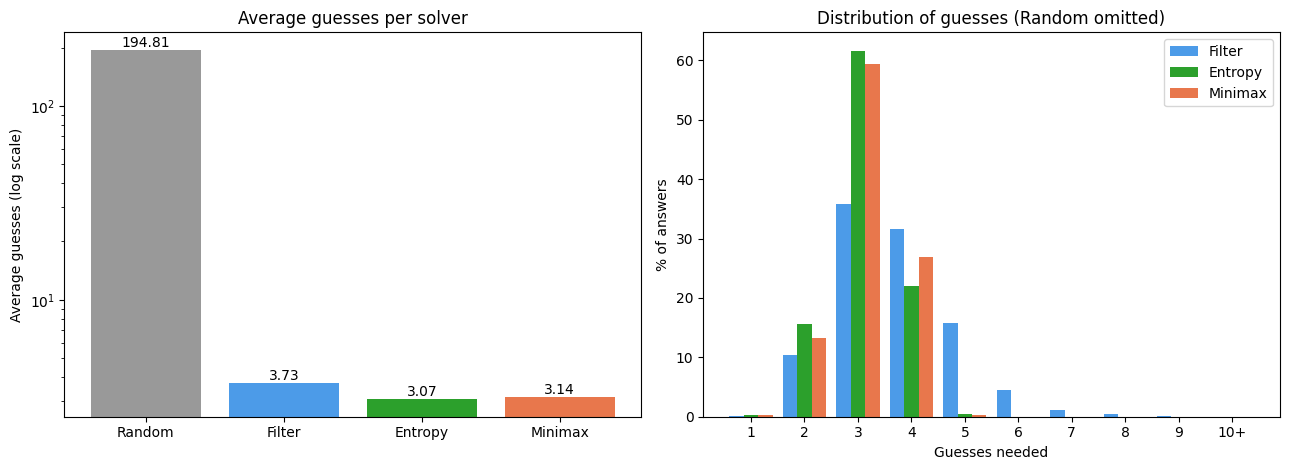

Saved: /content/drive/MyDrive/pokemon_wordle/results/results_table.csv and /content/drive/MyDrive/pokemon_wordle/results/benchmark_chart.png


In [5]:
import importlib, benchmark
importlib.reload(benchmark)
df = benchmark.run_all()